# 01 · Análisis exploratorio inicial (polars)

**Proyecto:** efecto de la comedicación en la vida real (Modalidad A, Ruta B).
Preguntas candidatas:

1. **Triple whammy**: IECA/ARA-II + diurético + AINE → lesión renal aguda (LRA)
2. **Anticoagulante + antiagregante** → sangrado

**Datos:** MIMIC-IV Clinical Database Demo **v2.2** (PhysioNet, 100 pacientes, licencia ODbL),
descargado el 2026-11-09. Formato **nativo** de MIMIC (módulos `hosp` / `icu`), *no* OMOP.

**Objetivo de esta libreta:** conocer los datos y hacer un **conteo de factibilidad**,
es decir, ver cuántas hospitalizaciones tienen cada combinación y cuántas presentan el desenlace.
Esta libreta es exploración; la lógica definitiva irá a `sql/` y `src/`.

> Las fechas de MIMIC están desplazadas al futuro (años 2100+) como parte de la desidentificación.
> Los intervalos entre fechas sí son reales.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

DATA = Path("../data/raw/mimic-iv-clinical-database-demo-2.2")
FIG = Path("../figuras")
FIG.mkdir(exist_ok=True)

pl.Config.set_tbl_rows(25)
pl.Config.set_fmt_str_lengths(60)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

C1, C2, C3 = "#3B6EA8", "#D9822B", "#7A9E4F"


def leer(modulo: str, tabla: str) -> pl.DataFrame:
    return pl.read_csv(DATA / modulo / f"{tabla}.csv.gz", try_parse_dates=True, infer_schema_length=None)


def guardar(fig, nombre: str) -> None:
    fig.savefig(FIG / f"{nombre}.png", bbox_inches="tight")

In [2]:
patients = leer("hosp", "patients")
admissions = leer("hosp", "admissions")
icustays = leer("icu", "icustays")
prescriptions = leer("hosp", "prescriptions")
labevents = leer("hosp", "labevents")
diagnoses = leer("hosp", "diagnoses_icd")

pl.DataFrame({
    "tabla": ["patients", "admissions", "icustays", "prescriptions", "labevents", "diagnoses_icd"],
    "filas": [len(t) for t in (patients, admissions, icustays, prescriptions, labevents, diagnoses)],
    "pacientes": [t["subject_id"].n_unique() for t in (patients, admissions, icustays, prescriptions, labevents, diagnoses)],
})

tabla,filas,pacientes
str,i64,i64
"""patients""",100,100
"""admissions""",275,100
"""icustays""",140,100
"""prescriptions""",18087,100
"""labevents""",107727,100
"""diagnoses_icd""",4506,100


## 1. Demografía

In [3]:
patients.select(
    pl.len().alias("n"),
    (pl.col("gender") == "F").sum().alias("mujeres"),
    pl.col("anchor_age").median().alias("edad_mediana"),
    pl.col("anchor_age").min().alias("edad_min"),
    pl.col("anchor_age").max().alias("edad_max"),
    pl.col("dod").is_not_null().sum().alias("fallecidos"),
)

n,mujeres,edad_mediana,edad_min,edad_max,fallecidos
u32,u32,f64,i64,i64,u32
100,43,63.0,21,91,31


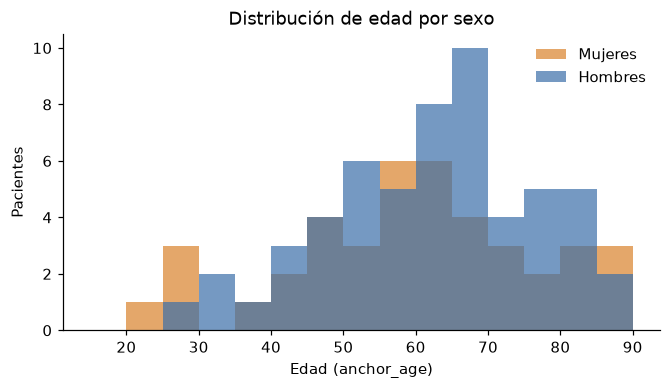

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for g, color in (("F", C2), ("M", C1)):
    ax.hist(patients.filter(pl.col("gender") == g)["anchor_age"], bins=range(15, 95, 5),
            alpha=0.7, color=color, label="Mujeres" if g == "F" else "Hombres")
ax.set(xlabel="Edad (anchor_age)", ylabel="Pacientes", title="Distribución de edad por sexo")
ax.legend(frameon=False)
guardar(fig, "01_edad_sexo")

## 2. Hospitalizaciones y estancias en UCI

In [5]:
adm = admissions.with_columns(
    ((pl.col("dischtime") - pl.col("admittime")).dt.total_hours() / 24).alias("los_dias")
)
resumen_adm = adm.select(
    pl.len().alias("hospitalizaciones"),
    pl.col("los_dias").median().alias("estancia_mediana_dias"),
    pl.col("hospital_expire_flag").sum().alias("muertes_intrahospitalarias"),
)
por_paciente = adm.group_by("subject_id").len().select(
    pl.col("len").median().alias("hosp_por_paciente_mediana"), pl.col("len").max().alias("hosp_por_paciente_max")
)
pl.concat([resumen_adm, por_paciente], how="horizontal")

hospitalizaciones,estancia_mediana_dias,muertes_intrahospitalarias,hosp_por_paciente_mediana,hosp_por_paciente_max
u32,f64,i64,f64,u32
275,4.833333,15,1.0,20


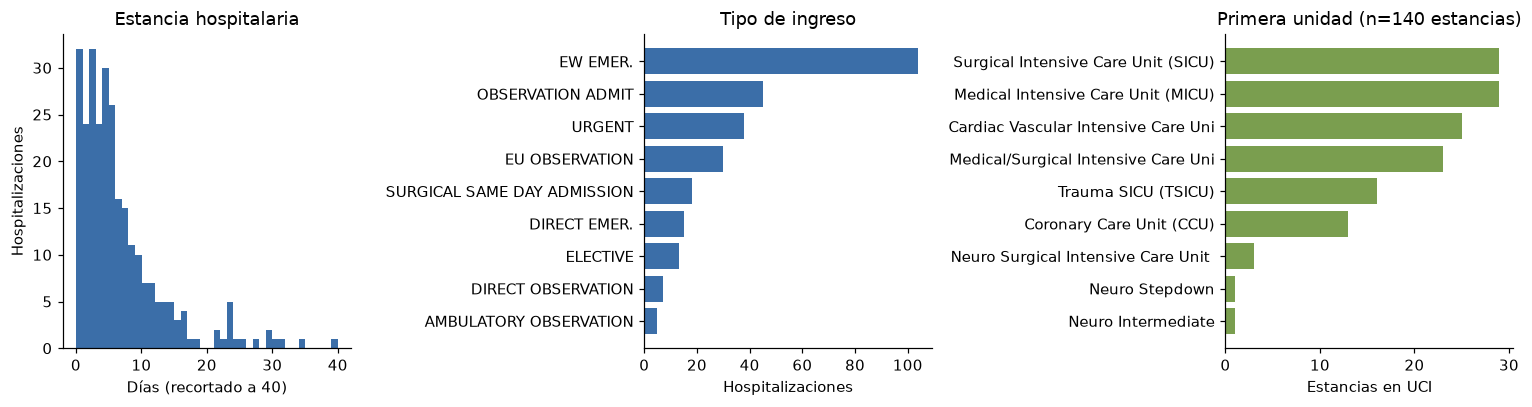

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

axes[0].hist(adm["los_dias"].clip(upper_bound=40), bins=40, color=C1)
axes[0].set(xlabel="Días (recortado a 40)", ylabel="Hospitalizaciones", title="Estancia hospitalaria")

tipos = adm.group_by("admission_type").len().sort("len")
axes[1].barh(tipos["admission_type"], tipos["len"], color=C1)
axes[1].set(xlabel="Hospitalizaciones", title="Tipo de ingreso")

unidades = icustays.group_by("first_careunit").len().sort("len")
axes[2].barh(unidades["first_careunit"].str.slice(0, 35), unidades["len"], color=C3)
axes[2].set(xlabel="Estancias en UCI", title=f"Primera unidad (n={len(icustays)} estancias)")

fig.tight_layout()
guardar(fig, "02_hospitalizaciones_uci")

## 3. Medicamentos

Primero, los fármacos más frecuentes. Después los clasificamos en las clases de interés.

**Decisiones de clasificación (revisables):**
- IECA con lista explícita, porque el patrón `pril` también atrapa *Lidocaine-Prilocaine*.
- Heparina: se excluyen *Flush*, *Dwell* y *Priming*, que son lavados o cebado de catéteres y no anticoagulación sistémica.
  Con solo el nombre no se distingue la dosis profiláctica de la terapéutica (**limitación**).
- Clasificar por texto es provisional; en OMOP se hará con RxNorm/ATC vía `concept_ancestor`.

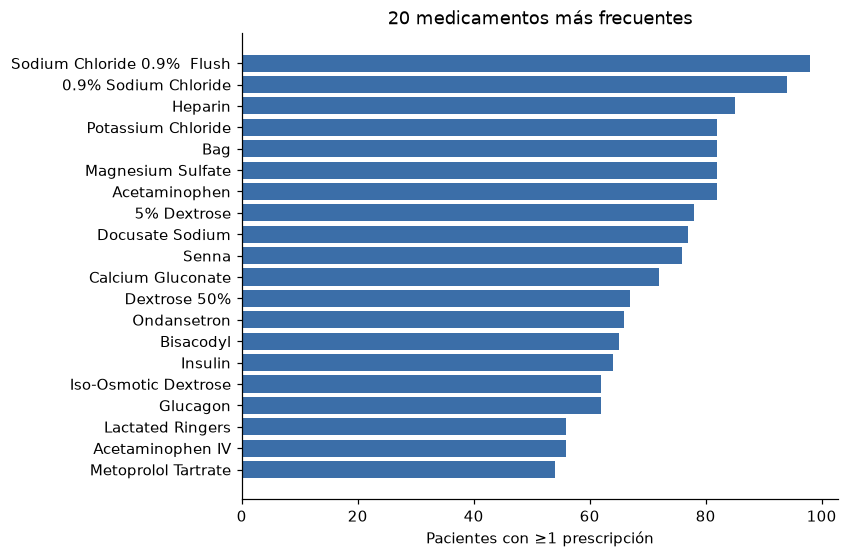

In [7]:
top = (
    prescriptions.group_by("drug")
    .agg(pl.col("subject_id").n_unique().alias("pacientes"))
    .sort("pacientes", descending=True)
    .head(20)
)
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(top["drug"].reverse(), top["pacientes"].reverse(), color=C1)
ax.set(xlabel="Pacientes con ≥1 prescripción", title="20 medicamentos más frecuentes")
guardar(fig, "03_top_medicamentos")

In [8]:
CLASES = {
    "IECA": r"(?i)^(lisinopril|captopril|enalapril|enalaprilat|ramipril|benazepril|quinapril|fosinopril)",
    "ARA-II": r"(?i)sartan",
    "Diurético": r"(?i)furosemide|torsemide|bumetanide|hydrochlorothiazide|chlorthalidone|metolazone|spironolactone",
    "AINE": r"(?i)ibuprofen|ketorolac|naproxen|celecoxib|diclofenac|indomethacin|meloxicam",
    "Anticoagulante": r"(?i)^heparin( sodium| \(iabp\)| \(hemodialysis\))?$|enoxaparin|warfarin|apixaban|rivaroxaban|dabigatran",
    "Antiagregante": r"(?i)aspirin|clopidogrel|ticagrelor|prasugrel",
}

clasif = pl.concat([
    prescriptions.filter(pl.col("drug").str.contains(patron)).with_columns(pl.lit(clase).alias("clase"))
    for clase, patron in CLASES.items()
])
# IECA y ARA-II se agrupan como bloqueo del sistema renina-angiotensina (SRA)
clasif = clasif.with_columns(
    pl.when(pl.col("clase").is_in(["IECA", "ARA-II"])).then(pl.lit("IECA/ARA-II")).otherwise("clase").alias("grupo")
)

conteo_clases = (
    clasif.group_by("clase")
    .agg(pl.col("subject_id").n_unique().alias("pacientes"), pl.col("hadm_id").n_unique().alias("hospitalizaciones"))
    .sort("pacientes", descending=True)
)
conteo_clases

clase,pacientes,hospitalizaciones
str,u32,u32
"""Anticoagulante""",89,201
"""Diurético""",59,120
"""Antiagregante""",51,107
"""AINE""",29,35
"""IECA""",26,46
"""ARA-II""",7,25


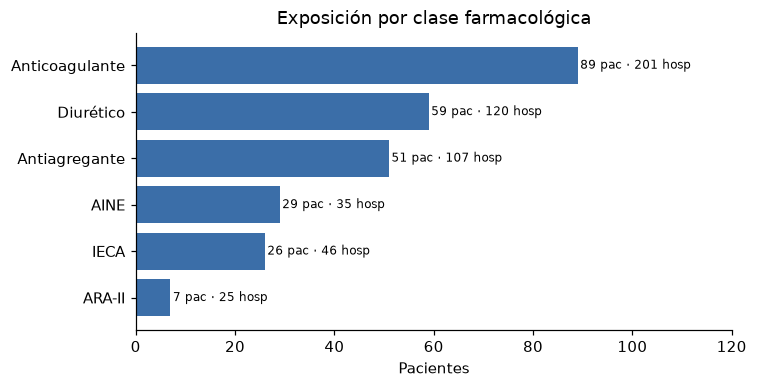

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.5))
c = conteo_clases.sort("pacientes")
ax.barh(c["clase"], c["pacientes"], color=C1)
for y, (p, h) in enumerate(zip(c["pacientes"], c["hospitalizaciones"])):
    ax.text(p + 0.5, y, f"{p} pac · {h} hosp", va="center", fontsize=8)
ax.set(xlabel="Pacientes", title="Exposición por clase farmacológica")
ax.set_xlim(0, c["pacientes"].max() * 1.35)
guardar(fig, "04_clases_farmacologicas")

## 4. Comedicación

Usamos dos definiciones de co-exposición, de la más laxa a la más estricta:

- **Misma hospitalización:** las clases aparecen en algún momento de la misma hospitalización, sin importar el orden.
- **Solapamiento temporal:** existe un intervalo en el que *todas* las clases están activas a la vez
  (`starttime`–`stoptime`; si falta `stoptime`, se usa el alta).

La segunda es la que tiene sentido farmacológico. La diferencia entre ambas ya sirve como análisis de sensibilidad.

In [10]:
intervalos = (
    clasif.join(adm.select("hadm_id", "dischtime"), on="hadm_id", how="left")
    .with_columns(pl.coalesce("stoptime", "dischtime").alias("fin"))
    .filter(pl.col("fin") > pl.col("starttime"))
    .select("subject_id", "hadm_id", "grupo", pl.col("starttime").alias("inicio"), "fin")
)


def misma_hosp(grupos: list[str]) -> pl.DataFrame:
    return (
        intervalos.group_by("hadm_id").agg(pl.col("grupo").unique())
        .filter(pl.col("grupo").list.set_intersection(grupos).list.len() == len(grupos))
        .select("hadm_id")
    )


def solapamiento(grupos: list[str]) -> pl.DataFrame:
    """Hospitalizaciones con un intervalo donde todas las clases están activas.
    Devuelve el inicio de la primera co-exposición (fecha índice candidata)."""
    base = intervalos.filter(pl.col("grupo") == grupos[0]).select("subject_id", "hadm_id", "inicio", "fin")
    for g in grupos[1:]:
        otro = intervalos.filter(pl.col("grupo") == g).select("hadm_id", pl.col("inicio").alias("i2"), pl.col("fin").alias("f2"))
        base = (
            base.join(otro, on="hadm_id")
            .with_columns(pl.max_horizontal("inicio", "i2").alias("inicio"), pl.min_horizontal("fin", "f2").alias("fin"))
            .filter(pl.col("inicio") < pl.col("fin"))
            .select("subject_id", "hadm_id", "inicio", "fin")
        )
    return base.group_by("subject_id", "hadm_id").agg(pl.col("inicio").min().alias("indice"))


ESCENARIOS = {
    "Double whammy\n(IECA/ARA-II + diurético)": ["IECA/ARA-II", "Diurético"],
    "Triple whammy\n(+ AINE)": ["IECA/ARA-II", "Diurético", "AINE"],
    "Anticoagulante +\nantiagregante": ["Anticoagulante", "Antiagregante"],
}

expo = {nombre: solapamiento(g) for nombre, g in ESCENARIOS.items()}
tabla_expo = pl.DataFrame({
    "escenario": [n.replace("\n", " ") for n in ESCENARIOS],
    "hosp_misma_hosp": [len(misma_hosp(g)) for g in ESCENARIOS.values()],
    "hosp_solapamiento": [len(expo[n]) for n in ESCENARIOS],
    "pacientes_solapamiento": [expo[n]["subject_id"].n_unique() for n in ESCENARIOS],
})
tabla_expo

escenario,hosp_misma_hosp,hosp_solapamiento,pacientes_solapamiento
str,i64,i64,i64
"""Double whammy (IECA/ARA-II + diurético)""",43,37,19
"""Triple whammy (+ AINE)""",4,3,3
"""Anticoagulante + antiagregante""",85,85,44


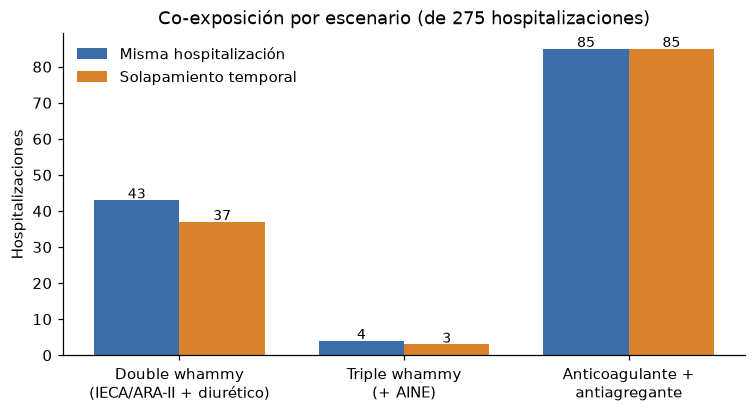

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = range(len(tabla_expo))
w = 0.38
ax.bar([i - w / 2 for i in x], tabla_expo["hosp_misma_hosp"], w, color=C1, label="Misma hospitalización")
ax.bar([i + w / 2 for i in x], tabla_expo["hosp_solapamiento"], w, color=C2, label="Solapamiento temporal")
for i, (a, b) in enumerate(zip(tabla_expo["hosp_misma_hosp"], tabla_expo["hosp_solapamiento"])):
    ax.text(i - w / 2, a + 0.5, a, ha="center", fontsize=9)
    ax.text(i + w / 2, b + 0.5, b, ha="center", fontsize=9)
ax.set_xticks(list(x), list(ESCENARIOS))
ax.set(ylabel="Hospitalizaciones", title=f"Co-exposición por escenario (de {len(adm)} hospitalizaciones)")
ax.legend(frameon=False)
guardar(fig, "05_coexposicion")

## 5. Desenlaces de laboratorio

Son definiciones **simplificadas**, solo para el conteo de factibilidad:

- **LRA (KDIGO, solo creatinina, itemid 50912):** aumento ≥ 0.3 mg/dL en ≤ 48 h, o ≥ 1.5× el valor mínimo previo en la hospitalización.
  No se usa el criterio de diuresis.
- **Sangrado (proxy, hemoglobina, itemid 51222):** caída ≥ 2 g/dL en ≤ 48 h.
  Es un proxy débil: también lo producen la hemodilución y las flebotomías.

In [12]:
def serie(itemid: int) -> pl.DataFrame:
    return (
        labevents.filter((pl.col("itemid") == itemid) & pl.col("valuenum").is_not_null() & pl.col("hadm_id").is_not_null())
        .select("subject_id", "hadm_id", "charttime", "valuenum")
        .sort("hadm_id", "charttime")
    )


creat = serie(50912)
hgb = serie(51222)


def eventos(df: pl.DataFrame, delta: float, sentido: int, ratio: float | None = None) -> pl.DataFrame:
    """Primer tiempo por hospitalización en que se cumple el criterio respecto a un valor previo.
    sentido=+1 busca aumentos (creatinina); sentido=-1 busca caídas (hemoglobina)."""
    pares = (
        df.join(df.select("hadm_id", pl.col("charttime").alias("t0"), pl.col("valuenum").alias("v0")), on="hadm_id")
        .filter(pl.col("t0") < pl.col("charttime"))
        .with_columns(((pl.col("charttime") - pl.col("t0")).dt.total_hours()).alias("horas"))
    )
    cond = ((pl.col("valuenum") - pl.col("v0")) * sentido >= delta) & (pl.col("horas") <= 48)
    if ratio is not None:
        cond = cond | (pl.col("valuenum") >= ratio * pl.col("v0"))
    return pares.filter(cond).group_by("subject_id", "hadm_id").agg(pl.col("charttime").min().alias("t_evento"))


lra = eventos(creat, 0.3, +1, ratio=1.5)
sangrado = eventos(hgb, 2.0, -1)

pl.DataFrame({
    "desenlace": ["LRA (creatinina)", "Caída de Hb ≥2 g/dL"],
    "hosp_con_≥2_mediciones": [
        creat.group_by("hadm_id").len().filter(pl.col("len") >= 2).height,
        hgb.group_by("hadm_id").len().filter(pl.col("len") >= 2).height,
    ],
    "hosp_con_evento": [lra.height, sangrado.height],
})

desenlace,hosp_con_≥2_mediciones,hosp_con_evento
str,i64,i64
"""LRA (creatinina)""",221,75
"""Caída de Hb ≥2 g/dL""",218,62


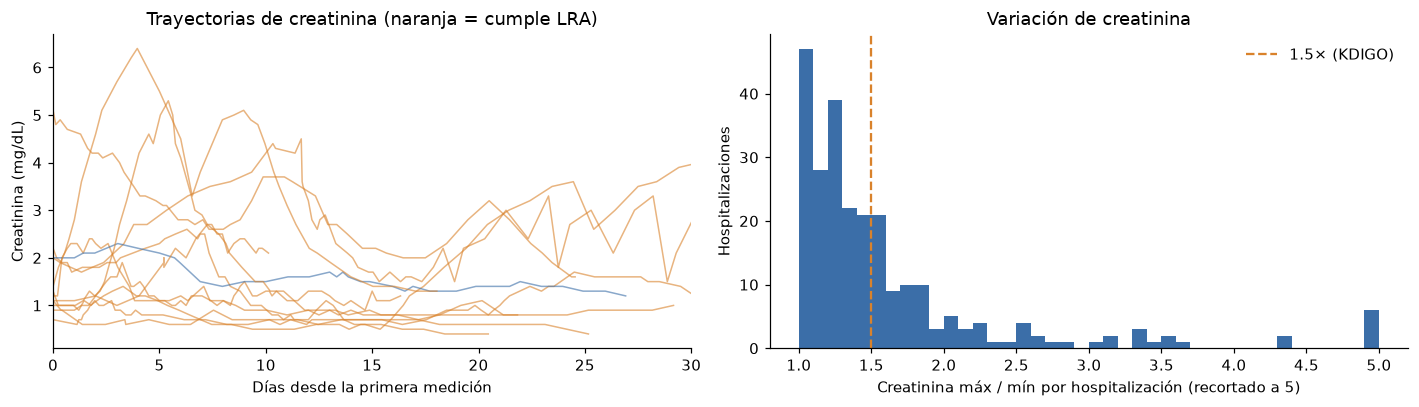

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))

# Trayectorias: horas desde la primera medición, para las 12 hospitalizaciones con más mediciones
top_h = creat.group_by("hadm_id").len().sort("len", descending=True).head(12)["hadm_id"].to_list()
tray = creat.filter(pl.col("hadm_id").is_in(top_h)).with_columns(
    ((pl.col("charttime") - pl.col("charttime").min().over("hadm_id")).dt.total_hours() / 24).alias("dia")
)
for h in top_h:
    t = tray.filter(pl.col("hadm_id") == h)
    color = C2 if h in lra["hadm_id"] else C1
    axes[0].plot(t["dia"], t["valuenum"], color=color, alpha=0.6, lw=1)
axes[0].set(xlabel="Días desde la primera medición", ylabel="Creatinina (mg/dL)",
            title="Trayectorias de creatinina (naranja = cumple LRA)")
axes[0].set_xlim(0, 30)

ratio = creat.group_by("hadm_id").agg((pl.col("valuenum").max() / pl.col("valuenum").min()).alias("r"))
axes[1].hist(ratio["r"].clip(upper_bound=5), bins=40, color=C1)
axes[1].axvline(1.5, color=C2, ls="--", label="1.5× (KDIGO)")
axes[1].set(xlabel="Creatinina máx / mín por hospitalización (recortado a 5)", ylabel="Hospitalizaciones",
            title="Variación de creatinina")
axes[1].legend(frameon=False)
fig.tight_layout()
guardar(fig, "06_creatinina")

## 6. Conteo de factibilidad

Para cada escenario se cuentan las hospitalizaciones con co-exposición (definición por solapamiento) y, entre ellas,
cuántas tienen el desenlace **después** de la fecha índice (inicio de la co-exposición).
Como referencia se incluye la tasa del desenlace en todas las hospitalizaciones con mediciones.

In [14]:
DESENLACE = {
    "Double whammy\n(IECA/ARA-II + diurético)": lra,
    "Triple whammy\n(+ AINE)": lra,
    "Anticoagulante +\nantiagregante": sangrado,
}

filas = []
for nombre, ex in expo.items():
    out = DESENLACE[nombre]
    con = ex.join(out, on=["subject_id", "hadm_id"], how="left").filter(pl.col("t_evento") > pl.col("indice"))
    filas.append({
        "escenario": nombre.replace("\n", " "),
        "expuestos_hosp": ex.height,
        "evento_post_indice": con.height,
    })
factibilidad = pl.DataFrame(filas).with_columns(
    (pl.col("evento_post_indice") / pl.col("expuestos_hosp") * 100).round(1).alias("%")
)
factibilidad

escenario,expuestos_hosp,evento_post_indice,%
str,i64,i64,f64
"""Double whammy (IECA/ARA-II + diurético)""",37,10,27.0
"""Triple whammy (+ AINE)""",3,2,66.7
"""Anticoagulante + antiagregante""",85,16,18.8


In [15]:
base_lra = lra.height / creat.group_by("hadm_id").len().filter(pl.col("len") >= 2).height * 100
base_hgb = sangrado.height / hgb.group_by("hadm_id").len().filter(pl.col("len") >= 2).height * 100
print(f"Referencia, LRA en hosp. con ≥2 creatininas: {base_lra:.1f}%")
print(f"Referencia, caída de Hb en hosp. con ≥2 hemoglobinas: {base_hgb:.1f}%")

Referencia, LRA en hosp. con ≥2 creatininas: 33.9%
Referencia, caída de Hb en hosp. con ≥2 hemoglobinas: 28.4%


## 7. Observaciones iniciales

**Población.** 100 pacientes (43 % mujeres, mediana de 63 años), 275 hospitalizaciones y 140 estancias en UCI.
Un paciente acumula 20 hospitalizaciones, así que el análisis tiene que considerar la agrupación por paciente.

**Triple whammy.** Con este tamaño **no es factible** como análisis principal: solo 3 hospitalizaciones
(3 pacientes) tienen las tres clases activas a la vez. En cambio, el **double whammy** (IECA/ARA-II + diurético)
sí tiene volumen razonable: 37 hospitalizaciones en 19 pacientes.

**Anticoagulante + antiagregante.** Es la combinación más frecuente (85 hospitalizaciones, 44 pacientes), pero
la clase "anticoagulante" está inflada por la heparina profiláctica subcutánea (89 de 100 pacientes la reciben).
Para que la pregunta tenga sentido habría que separar la dosis profiláctica de la terapéutica, con `dose_val_rx`
y la vía de administración.

**Desenlaces.** Con la definición simplificada, la LRA aparece en el 34 % de las hospitalizaciones con ≥2 creatininas
y la caída de Hb en el 28 %. Las tasas en los expuestos (27 % y 19 %) **no son comparables** con estas tasas de
referencia: no hay ajuste por confusores ni ventanas de seguimiento equivalentes.

**Siguientes pasos sugeridos**
1. Pregunta principal: **double whammy → LRA**, con el triple whammy como análisis secundario descriptivo.
   La alternativa es anticoagulación *terapéutica* + antiagregante → sangrado.
2. Definir el comparador (p. ej., IECA/ARA-II sin diurético), la ventana de lavado y el seguimiento (p. ej., 7 días).
3. Llevar los datos a OMOP (DuckDB) y reescribir las clases con RxNorm/ATC y las definiciones en SQL.